# Online Retail Analysis

Analyze retail revenue, returns and seasonal patterns using the complete Online Retail II dataset. This notebook uses the same cleaning and validation rules as the Python pipeline.

In [1]:
from pathlib import Path
import sys
root = Path.cwd().resolve()
if root.name == "code":
    root = root.parent
if not (root / "code" / "retail_pipeline").is_dir():
    raise RuntimeError("Open this notebook from the project root or code directory.")
sys.path.insert(0, str(root / "code"))
from retail_pipeline.config import load
from retail_pipeline.prepare import prepare
from retail_pipeline.pipeline import run
config = load()

## Data Preparation

The two full yearly CSVs are included. If they are missing, recreate them from the original workbook.

In [2]:
if not list((root / "data" / "raw").glob("Year_*_online_retail_II.csv")):
    prepare(config)

## Cleaning and Analysis

Run ingestion, validation, the star schema and analytics. Repeating this cell does not duplicate already ingested normalized rows.

In [3]:
summary = run(config)
summary

input_rows: 1067371
new_rows: 0
raw_rows: 1033036
profiling.missing_customer: 235151
profiling.missing_date: 0
profiling.negative_quantity: 22496
profiling.negative_price: 5
checks.dim_country_orphans: 0
checks.dim_date_orphans: 0
checks.dim_product_orphans: 0
checks.dim_customer_orphans: 0
checks.invalid_staging: 0
checks.missing_fact_rows: 0
staging_rows: 1031644
fact_rows: 1031644
net_revenue: 19097536.1680


{'input_rows': 1067371,
 'new_rows': 0,
 'raw_rows': 1033036,
 'profiling': {'missing_customer': 235151,
  'missing_date': 0,
  'negative_quantity': 22496,
  'negative_price': 5},
 'checks': {'dim_country_orphans': 0,
  'dim_date_orphans': 0,
  'dim_product_orphans': 0,
  'dim_customer_orphans': 0,
  'invalid_staging': 0,
  'missing_fact_rows': 0},
 'staging_rows': 1031644,
 'fact_rows': 1031644,
 'net_revenue': '19097536.1680'}

## Daily KPIs

In [4]:
import pandas as pd
daily = pd.read_csv(root / "data" / "processed" / "daily_kpis.csv", parse_dates=["full_date"])
daily.head()

,full_date,year,month,month_name,daily_orders,gross_revenue,returned_revenue,net_revenue,is_q4
0,2009-12-01,2009,12,December,165,54347.23,1335.37,53011.86,1
1,2009-12-02,2009,12,December,132,63172.58,519.35,62653.23,1
2,2009-12-03,2009,12,December,148,73972.45,3940.42,70032.03,1
3,2009-12-04,2009,12,December,107,40581.26,386.52,40194.74,1
4,2009-12-05,2009,12,December,32,9803.05,0.00,9803.05,1


## Revenue Visualizations

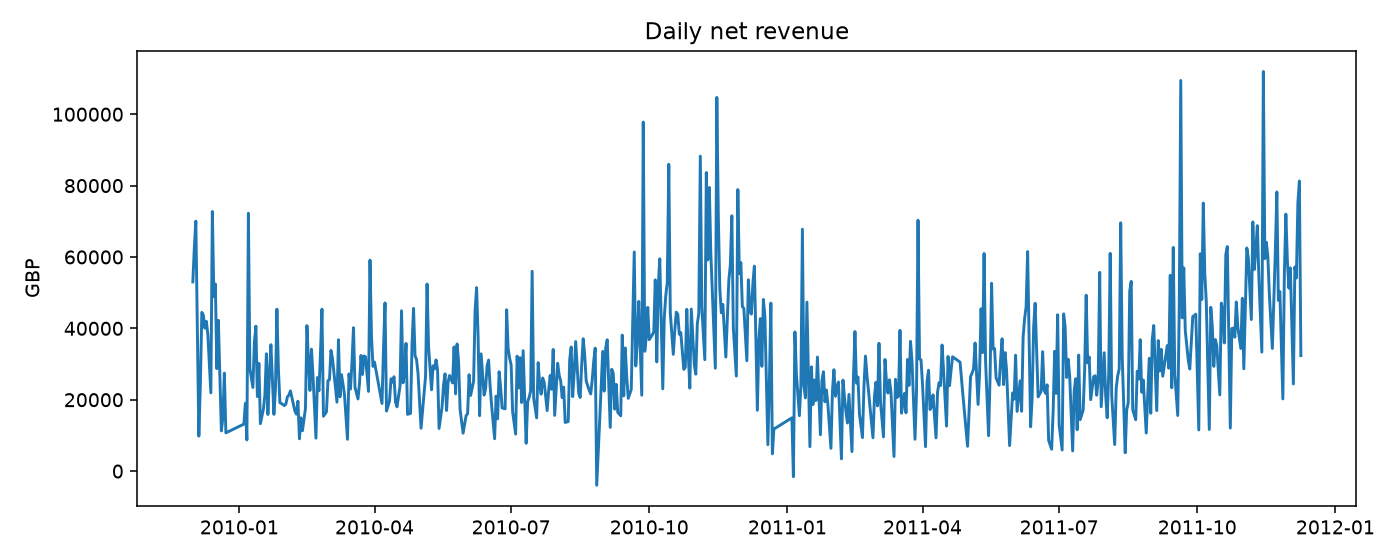

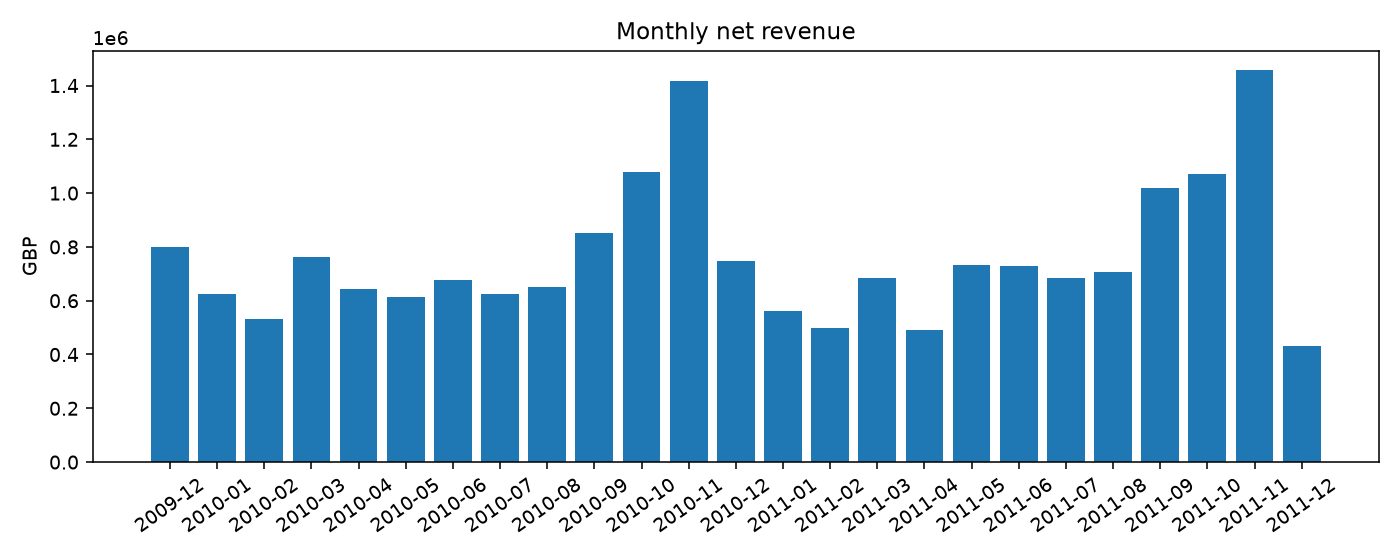

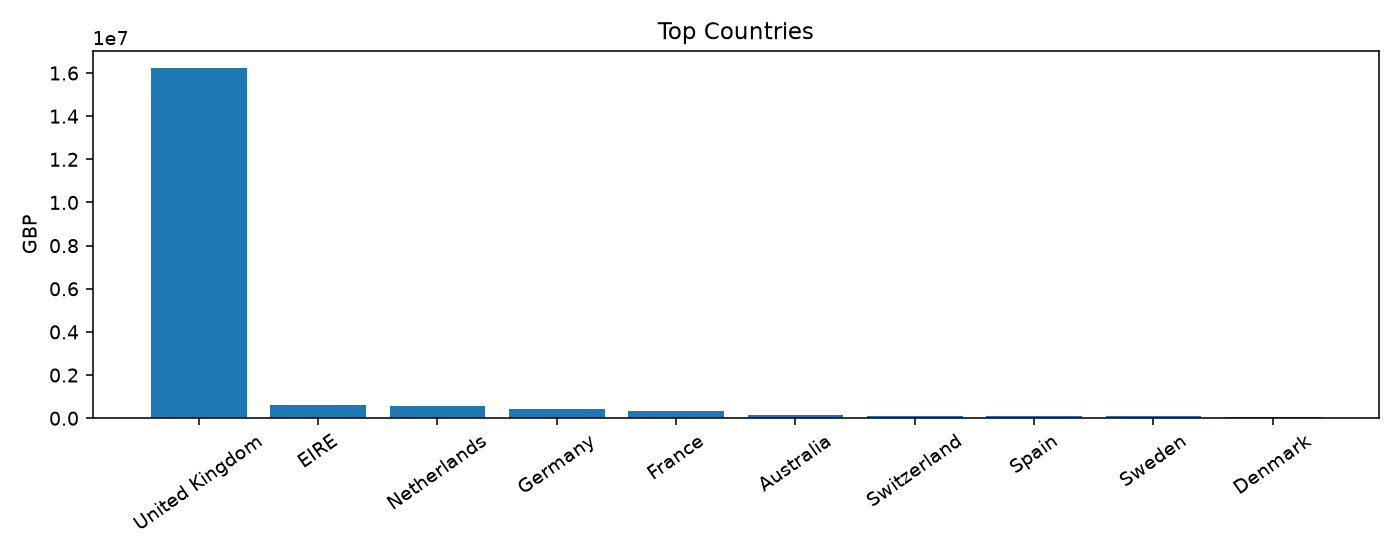

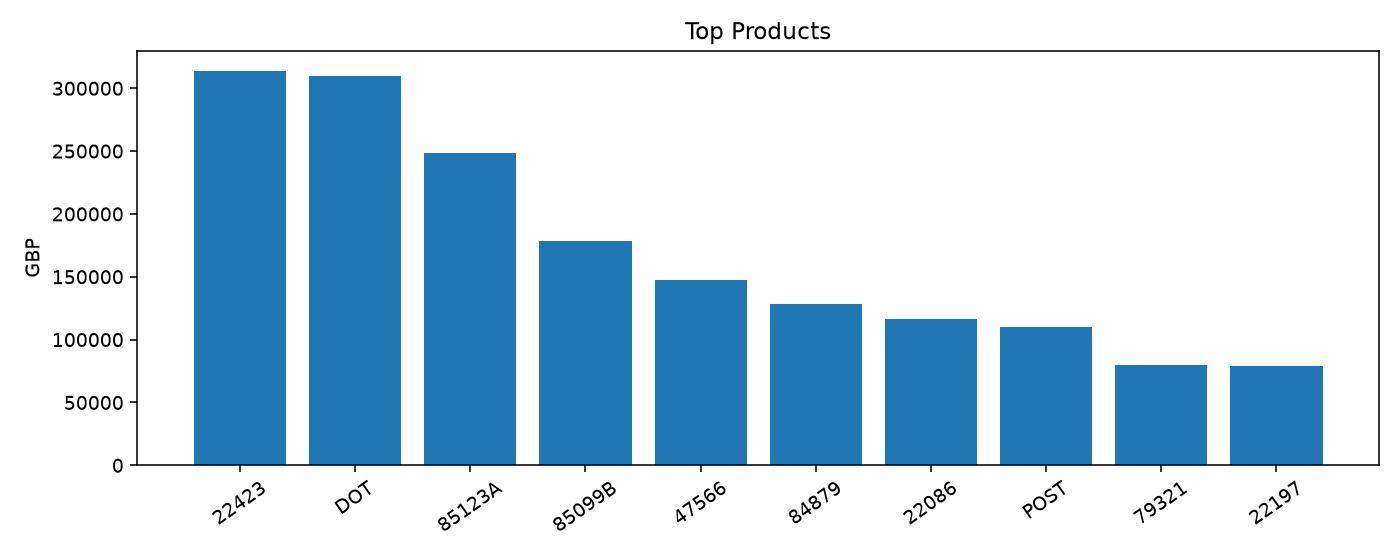

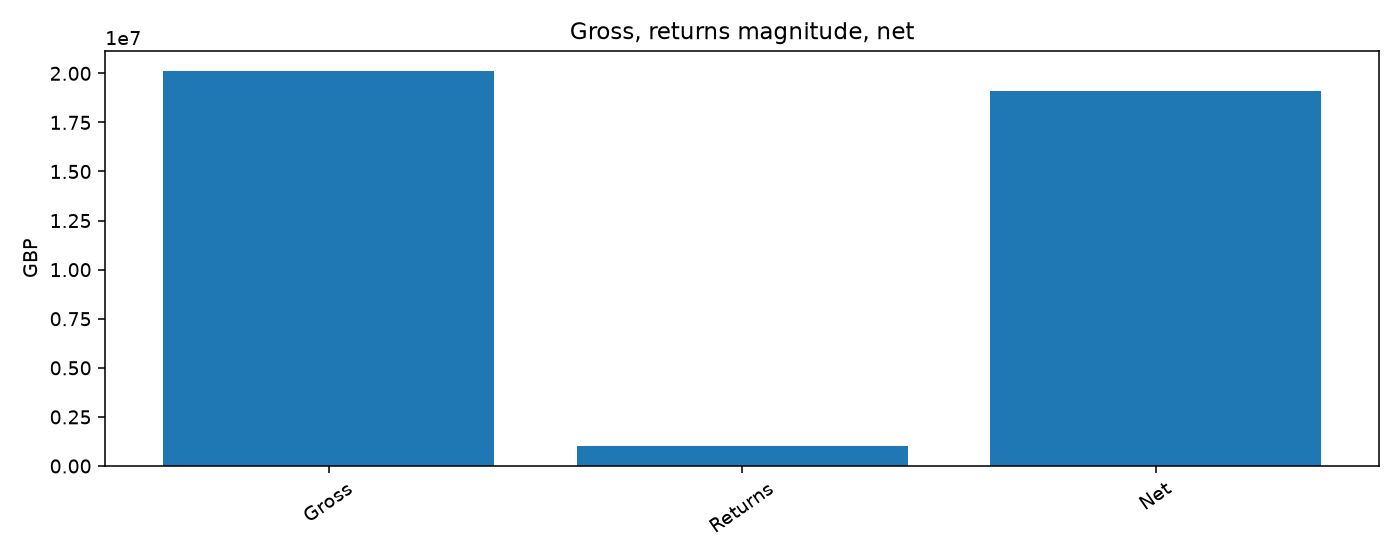

In [5]:
from IPython.display import display, Image
for name in ["daily_revenue", "monthly_revenue", "top_countries", "top_products", "revenue_breakdown"]:
    display(Image(filename=str(root / "reports" / "figures" / (name + ".png"))))

## Statistical Results

These exploratory comparisons do not establish a causal Q4 effect. Daily observations may be temporally dependent, and the last December is incomplete.

In [6]:
print((root / "reports" / "q4_stats_tests_report.txt").read_text())
print((root / "reports" / "q4_regression_report.txt").read_text())

Exploratory Q4 vs non-Q4 analysis. Observed trading days only; no zero-fill.

Daily observations may be autocorrelated. P-values are descriptive, not causal.

net_revenue: n_q4=153, n_non_q4=451, mean_difference=18959.395485, t=11.738320, p=1.3798719e-24, df=201.616, 95% CI=[15774.600994, 22144.189976]

return_rate: n_q4=153, n_non_q4=451, mean_difference=0.000465, t=0.052423, p=0.95822633, df=304.827, 95% CI=[-0.016978, 0.017907]

                            OLS Regression Results                            
Dep. Variable:          daily_revenue   R-squared:                       0.482
Model:                            OLS   Adj. R-squared:                  0.480
Method:                 Least Squares   F-statistic:                     203.6
Date:                Wed, 14 Oct 2026   Prob (F-statistic):           3.06e-68
Time:                        13:01:09   Log-Likelihood:                -6525.4
No. Observations:                 604   AIC:                         1.306e+04
Df Residual

## Data Attribution

Chen, D. (2012). Online Retail II. UCI Machine Learning Repository. https://doi.org/10.24432/C5CG6D. Dataset license: CC BY 4.0. Source details: `code/docs/DATA_ATTRIBUTION.md`.